In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import numpy as np
#Daten die gebraucht werden laden...
import pandas as pd
diebstahl=diebstahl = pd.read_csv(
    "Fahrraddiebstahl.csv",
    sep=",",
    dtype={"LOR": str},
    encoding='latin1'
)
bezirke = pd.read_csv(
    "bezirke.csv",
    sep=";",
    dtype={"PLR_ID": str},
    encoding='latin1'
)

In [38]:
#Wir möchten die beiden Datensätze über eine gemeinsame Kennung verbinden:

#Fahrraddiebstahl (LOR) → Bezirksübersicht (PLR_ID) → Bezirk
# IDs als Text speichern
diebstahl["LOR"] = diebstahl["LOR"].astype("string").str.zfill(8)
bezirke["PLR_ID"] = bezirke["PLR_ID"].astype("string").str.zfill(8)
#LOR	Gibt an, in welchem kleinen Gebiet (Planungsraum) das Fahrrad gestohlen wurde.
#PLR_ID	Ist die ID dieses kleinen Gebiets in deiner Bezirksübersicht.
#BEZ_ID	Ist die ID des gesamten Berliner Bezirks, z. B. Mitte.
# Tabellen verbinden
df = pd.merge(
    diebstahl, #tabelle links
    bezirke[["PLR_ID", "BEZ", "PGR", "BZR"]],#tabelle rechts
    left_on="LOR",# LOR wird verwendet
    right_on="PLR_ID",
    how="left",
    validate="many_to_one"
)

df.head()

,ANGELEGT_AM,TATZEIT_ANFANG_DATUM,TATZEIT_ANFANG_STUNDE,TATZEIT_ENDE_DATUM,TATZEIT_ENDE_STUNDE,LOR,SCHADENSHOEHE,VERSUCH,ART_DES_FAHRRADS,DELIKT,ERFASSUNGSGRUND,PLR_ID,BEZ,PGR,BZR
0,22.11.2026,21.11.2026,14,21.11.2026,19,04501149,1400,Nein,Fahrrad,Fahrraddiebstahl,Sonstiger schwerer Diebstahl von Fahrrädern,04501149,Charlottenburg-Wilmersdorf,Wilmersdorf Zentrum,Volkspark Wilmersdorf
1,22.11.2026,22.11.2026,18,22.11.2026,20,11400927,3000,Nein,Rennrad,Fahrraddiebstahl,Sonstiger schwerer Diebstahl von Fahrrädern,11400927,Lichtenberg,Lichtenberg Mitte,Neu-Lichtenberg
2,22.11.2026,21.11.2026,17,21.11.2026,18,08100311,1500,Nein,Fahrrad,Fahrraddiebstahl,Sonstiger schwerer Diebstahl von Fahrrädern,08100311,NeukÃ¶lln,NeukÃ¶lln,ReuterstraÃe
3,22.11.2026,21.11.2026,17,22.11.2026,1,06300526,3500,Nein,Mountainbike,Fahrraddiebstahl,Sonstiger schwerer Diebstahl von Fahrrädern,06300526,Steglitz-Zehlendorf,Zehlendorf SÃ¼d/Lichterfelde West,Teltower Damm
4,22.11.2026,21.11.2026,14,22.11.2026,14,12100103,844,Nein,Fahrrad,Fahrraddiebstahl,Sonstiger schwerer Diebstahl von Fahrrädern,12100103,Reinickendorf,Reinickendorf Ost,Ost 1 - ReginhardstraÃe


In [39]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32794 entries, 0 to 32793
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   ANGELEGT_AM            32794 non-null  object
 1   TATZEIT_ANFANG_DATUM   32794 non-null  object
 2   TATZEIT_ANFANG_STUNDE  32794 non-null  int64 
 3   TATZEIT_ENDE_DATUM     32794 non-null  object
 4   TATZEIT_ENDE_STUNDE    32794 non-null  int64 
 5   LOR                    32794 non-null  string
 6   SCHADENSHOEHE          32794 non-null  int64 
 7   VERSUCH                32794 non-null  object
 8   ART_DES_FAHRRADS       32794 non-null  object
 9   DELIKT                 32794 non-null  object
 10  ERFASSUNGSGRUND        32794 non-null  object
 11  PLR_ID                 32794 non-null  string
 12  BEZ                    32794 non-null  object
 13  PGR                    32794 non-null  object
 14  BZR                    32794 non-null  object
dtypes: int64(3), object

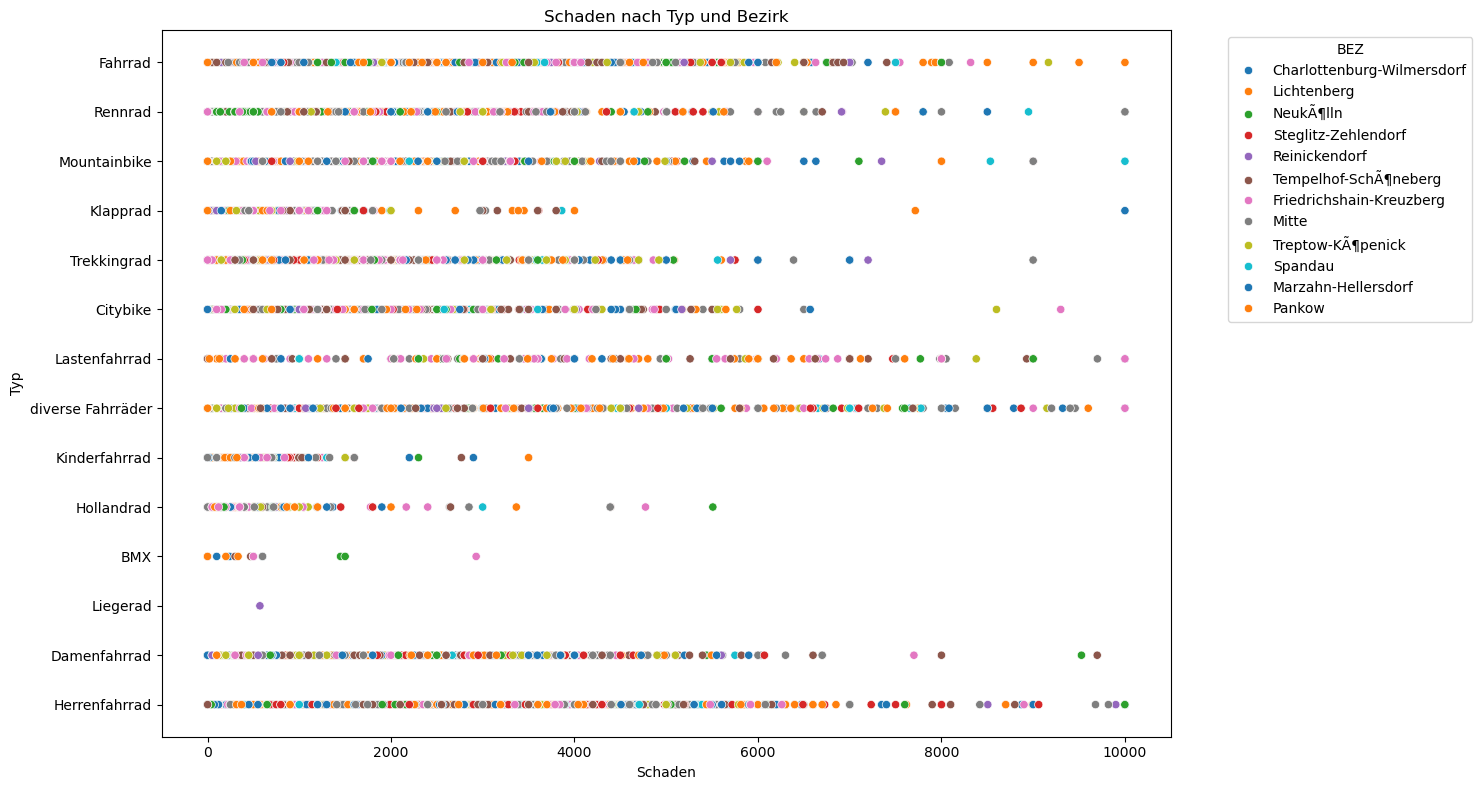

In [40]:
plt.figure(figsize=(15, 8))
sns.scatterplot(
    data=df,
    x="SCHADENSHOEHE",
    y="ART_DES_FAHRRADS",
    hue="BEZ",
    palette="tab10"
)

plt.xlabel("Schaden")
plt.ylabel("Typ")
plt.title("Schaden nach Typ und Bezirk")
plt.legend(title="BEZ", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [41]:
#nein heißt erfolgreich -> für erfolgsrate 
df["ERFOLGREICH"] = (df["VERSUCH"] == "Nein").astype(int)

In [53]:
#ich hoffe wenn man auf lor ebene schaut kommt man später drauf, dass ähnliche muster im gleichen bezirk sind
lor_stats = df.groupby("LOR").agg(
    ANZAHL_DIEBSTAHL=("LOR", "count"),
    DURCHSCHNITT_SCHADEN=("SCHADENSHOEHE", "mean"),
    MEDIAN_SCHADEN=("SCHADENSHOEHE", "median"),
    ERFOLGSQUOTE=("ERFOLGREICH", "mean"),
    BEZ=("BEZ", "first"),
    PGR=("PGR", "first"),
    BZR=("BZR", "first")

).reset_index()

lor_stats["ERFOLGSQUOTE"] = lor_stats["ERFOLGSQUOTE"] * 100

print(lor_stats.head())

        LOR  ANZAHL_DIEBSTAHL  DURCHSCHNITT_SCHADEN  MEDIAN_SCHADEN  \
0  01100101                48           1285.875000          1068.5   
1  01100102               230           1805.634783          1494.5   
2  01100103               139           1164.266187           857.0   
3  01100104               101           1372.277228          1100.0   
4  01100205                55           1687.963636          1592.0   

   ERFOLGSQUOTE    BEZ      PGR                BZR  
0     97.916667  Mitte  Zentrum    Tiergarten SÃ¼d  
1     99.130435  Mitte  Zentrum    Tiergarten SÃ¼d  
2     99.280576  Mitte  Zentrum    Tiergarten SÃ¼d  
3    100.000000  Mitte  Zentrum    Tiergarten SÃ¼d  
4    100.000000  Mitte  Zentrum  Regierungsviertel  


In [54]:
#standartisierung ist wohl sehr wichtig. damit nicht große werte mehr einfluss haben...
from sklearn.preprocessing import StandardScaler
features = [
    "ANZAHL_DIEBSTAHL",
    "DURCHSCHNITT_SCHADEN",
    "MEDIAN_SCHADEN",
    "ERFOLGSQUOTE"
]
#bez ist string darum nicht für kmeans nutzbar aber wird vllt später gebraucht? 
X = lor_stats[features]

# StandardScaler erstellen
scaler = StandardScaler()

# daten standardisieren
X_scaled = scaler.fit_transform(X)

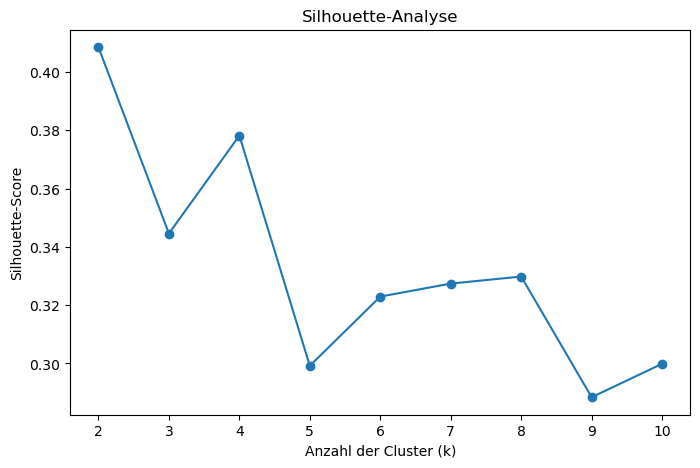

In [55]:
from sklearn.metrics import silhouette_score
#https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html#sphx-glr-auto-examples-cluster-plot-kmeans-silhouette-analysis-py
silhouette_values = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_values.append(score)


# ergebnisse darstellen
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_values, marker="o")

plt.xlabel("Anzahl der Cluster (k)")
plt.ylabel("Silhouette-Score")
plt.title("Silhouette-Analyse")

plt.show()

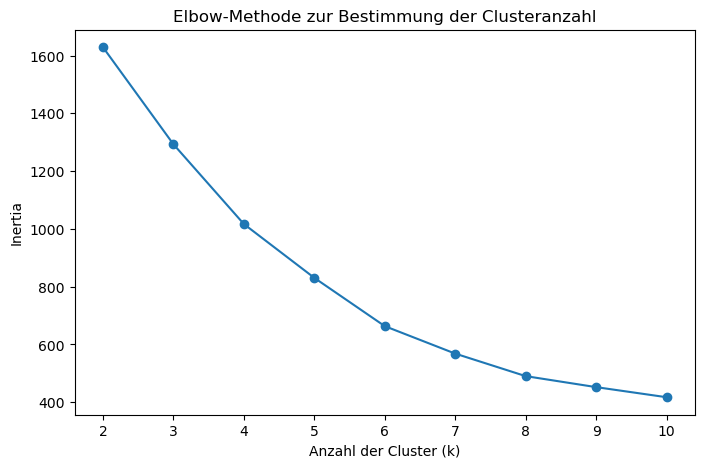

In [56]:
#das ist als zusatz nutzt man wohl in kombi mit silhouette
# Werte für die Anzahl der Cluster testen
inertia_values = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    # Summe der quadrierten Abstände speichern
    inertia_values.append(kmeans.inertia_)


# Ergebnisse visualisieren
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia_values, marker="o")

plt.xlabel("Anzahl der Cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow-Methode zur Bestimmung der Clusteranzahl")

plt.show()

#wenn man beide anschaut würde ich sagen 4 wäre gute clusteranzahl

In [57]:
# kmeans mit 4 clustern
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)
lor_stats["CLUSTER"] = kmeans.fit_predict(X_scaled)

# bissl unnoetig die visualisierung aber was solls hahah
print(lor_stats.head(10))

        LOR  ANZAHL_DIEBSTAHL  DURCHSCHNITT_SCHADEN  MEDIAN_SCHADEN  \
0  01100101                48           1285.875000          1068.5   
1  01100102               230           1805.634783          1494.5   
2  01100103               139           1164.266187           857.0   
3  01100104               101           1372.277228          1100.0   
4  01100205                55           1687.963636          1592.0   
5  01100206               252           1597.873016          1399.0   
6  01100207               160           1630.693750          1360.0   
7  01100308               289           1654.768166          1420.0   
8  01100309               304           1443.023026          1098.0   
9  01100310               229           1442.729258          1150.0   

   ERFOLGSQUOTE    BEZ      PGR                BZR  CLUSTER  
0     97.916667  Mitte  Zentrum    Tiergarten SÃ¼d        0  
1     99.130435  Mitte  Zentrum    Tiergarten SÃ¼d        3  
2     99.280576  Mitte  Zentrum 

In [58]:
# durchschnittswerte der einzelnen Cluster berechnen
cluster_analysis = lor_stats.groupby("CLUSTER")[features].mean()

print(cluster_analysis.round(2))

         ANZAHL_DIEBSTAHL  DURCHSCHNITT_SCHADEN  MEDIAN_SCHADEN  ERFOLGSQUOTE
CLUSTER                                                                      
0                   39.69               1183.13          799.90         99.71
1                   21.00               1115.00          772.66         91.09
2                   24.70               1990.34         1594.34         99.92
3                  157.99               1278.29          949.97         99.21


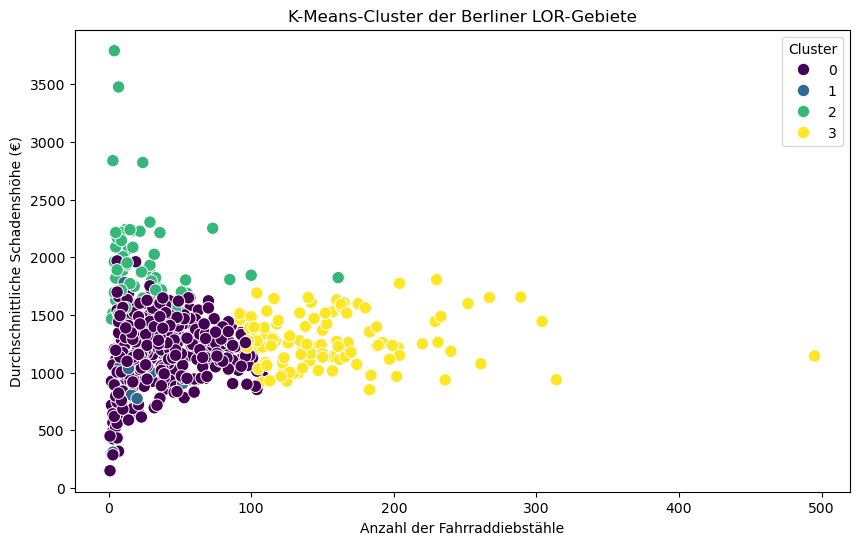

In [59]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=lor_stats,
    x="ANZAHL_DIEBSTAHL",
    y="DURCHSCHNITT_SCHADEN",
    hue="CLUSTER",
    palette="viridis",
    s=80
)

plt.xlabel("Anzahl der Fahrraddiebstähle")
plt.ylabel("Durchschnittliche Schadenshöhe (€)")
plt.title("K-Means-Cluster der Berliner LOR-Gebiete")

plt.legend(title="Cluster")
plt.show()

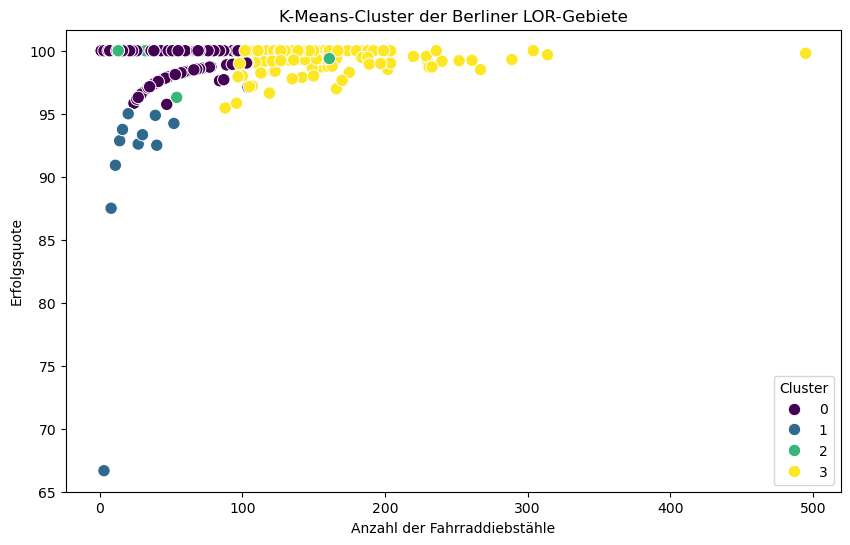

In [60]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=lor_stats,
    x="ANZAHL_DIEBSTAHL",
    y="ERFOLGSQUOTE",
    hue="CLUSTER",
    palette="viridis",
    s=80
)

plt.xlabel("Anzahl der Fahrraddiebstähle")
plt.ylabel("Erfolgsquote")
plt.title("K-Means-Cluster der Berliner LOR-Gebiete")

plt.legend(title="Cluster")
plt.show()

In [76]:
kreuztabellebez = pd.crosstab(
    lor_stats["BEZ"],
    lor_stats["CLUSTER"]
)

print(kreuztabellebez)

CLUSTER                      0  1   2   3
BEZ                                      
Charlottenburg-Wilmersdorf  40  1   4   7
Friedrichshain-Kreuzberg    14  0   0  22
Lichtenberg                 32  1   3   5
Marzahn-Hellersdorf         34  3   4   0
Mitte                       18  0   1  30
NeukÃ¶lln                   27  3   6  10
Pankow                      48  1   0  10
Reinickendorf               31  1   2   1
Spandau                     28  1  14   2
Steglitz-Zehlendorf         30  2   8   3
Tempelhof-SchÃ¶neberg       27  1   5  14
Treptow-KÃ¶penick           28  2   9   3


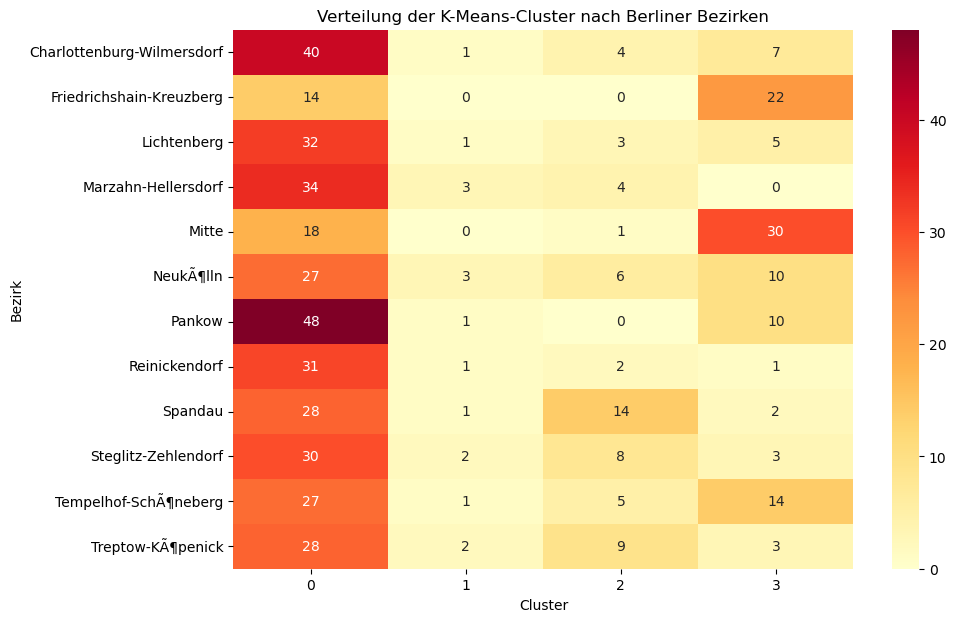

CLUSTER                        0    1     2     3
BEZ                                              
Charlottenburg-Wilmersdorf  76.9  1.9   7.7  13.5
Friedrichshain-Kreuzberg    38.9  0.0   0.0  61.1
Lichtenberg                 78.0  2.4   7.3  12.2
Marzahn-Hellersdorf         82.9  7.3   9.8   0.0
Mitte                       36.7  0.0   2.0  61.2
NeukÃ¶lln                   58.7  6.5  13.0  21.7
Pankow                      81.4  1.7   0.0  16.9
Reinickendorf               88.6  2.9   5.7   2.9
Spandau                     62.2  2.2  31.1   4.4
Steglitz-Zehlendorf         69.8  4.7  18.6   7.0
Tempelhof-SchÃ¶neberg       57.4  2.1  10.6  29.8
Treptow-KÃ¶penick           66.7  4.8  21.4   7.1


In [77]:

plt.figure(figsize=(10, 7))

sns.heatmap(
    kreuztabellebez,
    annot=True,
    fmt="d",
    cmap="YlOrRd"
)

plt.title("Verteilung der K-Means-Cluster nach Berliner Bezirken")
plt.xlabel("Cluster")
plt.ylabel("Bezirk")

plt.show()

kreuztabelle_prozent = pd.crosstab(
    lor_stats["BEZ"],
    lor_stats["CLUSTER"],
    normalize="index"
) * 100

print(kreuztabelle_prozent.round(1))
#wenn man oben schaut, wäre cluster 2 am besten, also auf nach spandau ;)

/usr/lib/python3.14/site-packages/seaborn/utils.py:61: UserWarning: Glyph 159 (\x9f) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/tmp/ipykernel_20971/898016605.py:18: UserWarning: Glyph 159 (\x9f) missing from font(s) DejaVu Sans.
  plt.savefig("test.png")
/home/charlotte/.local/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 159 (\x9f) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


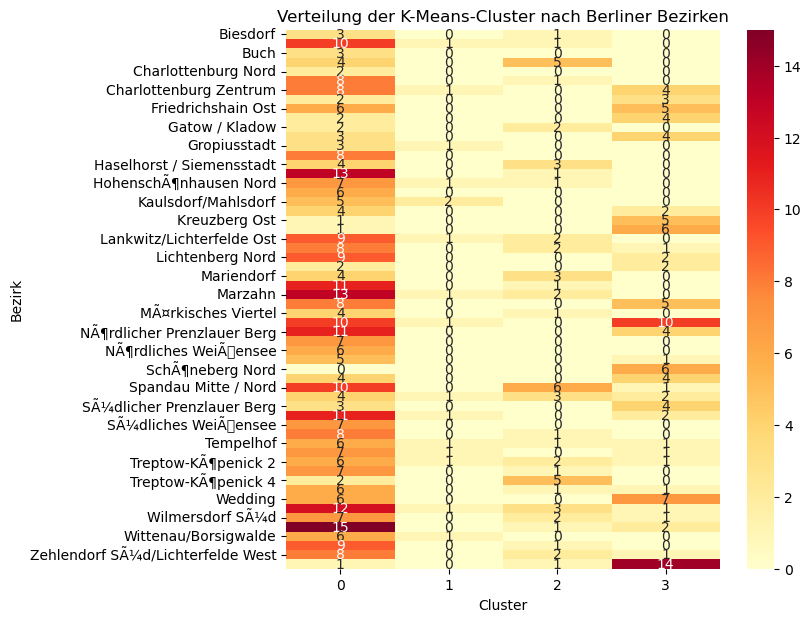

CLUSTER                                0     1     2      3
PGR                                                        
Biesdorf                            75.0   0.0  25.0    0.0
Britz/Buckow                        83.3   8.3   8.3    0.0
Buch                               100.0   0.0   0.0    0.0
Buckow Nord/Rudow                   44.4   0.0  55.6    0.0
Charlottenburg Nord                100.0   0.0   0.0    0.0
Charlottenburg West                 88.9   0.0  11.1    0.0
Charlottenburg Zentrum              61.5   7.7   0.0   30.8
Friedenau                           40.0   0.0   0.0   60.0
Friedrichshain Ost                  54.5   0.0   0.0   45.5
Friedrichshain West                 33.3   0.0   0.0   66.7
Gatow / Kladow                      50.0   0.0  50.0    0.0
Gesundbrunnen                       42.9   0.0   0.0   57.1
Gropiusstadt                        75.0  25.0   0.0    0.0
GrÃ¼ner Norden                     100.0   0.0   0.0    0.0
Haselhorst / Siemensstadt           57.1

In [79]:
#neue idee auf unterbezirk schauen, weil das hoffentlich noch genauer wird, yay. dafür passen ichs oben an
kreuztabellepgr = pd.crosstab(
    lor_stats["PGR"],
    lor_stats["CLUSTER"]
)
plt.figure(figsize=(7, 7))

sns.heatmap(
    kreuztabellepgr,
    annot=True,
    fmt="d",
    cmap="YlOrRd"
)

plt.title("Verteilung der K-Means-Cluster nach Berliner Bezirken")
plt.xlabel("Cluster")
plt.ylabel("Bezirk")
plt.savefig("test.png")
plt.show()

kreuztabelle_prozent_pgr = pd.crosstab(
    lor_stats["PGR"],
    lor_stats["CLUSTER"],
    normalize="index"
) * 100

print(kreuztabelle_prozent_pgr.round(1))

/usr/lib/python3.14/site-packages/seaborn/utils.py:61: UserWarning: Glyph 159 (\x9f) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/home/charlotte/.local/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 159 (\x9f) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


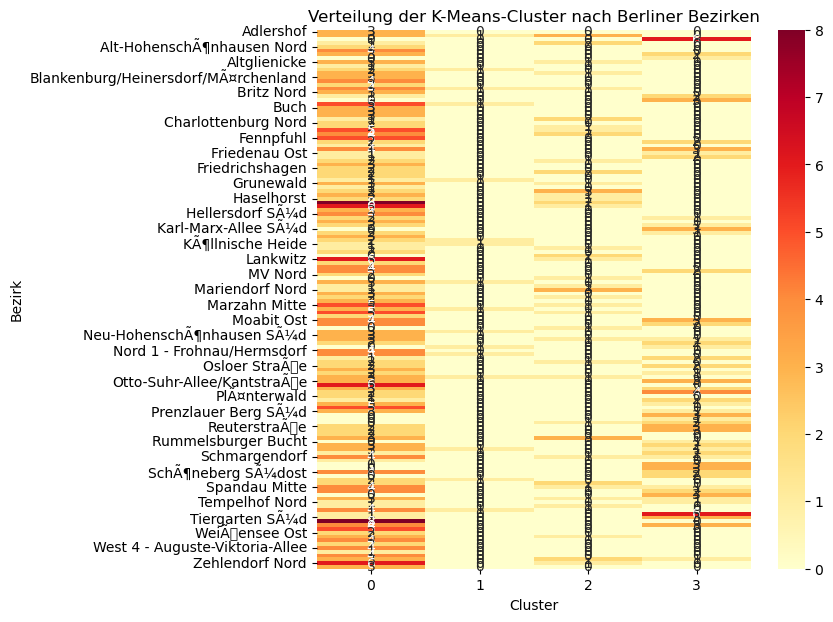

CLUSTER                         0     1     2      3
BZR                                                 
Adlershof                   100.0   0.0   0.0    0.0
AlbrechtstraÃe              42.9  14.3  42.9    0.0
Alexanderplatz                0.0   0.0   0.0  100.0
Allende-Viertel              33.3   0.0  66.7    0.0
Alt-HohenschÃ¶nhausen Nord  100.0   0.0   0.0    0.0
...                           ...   ...   ...    ...
West 5 - Tegel              100.0   0.0   0.0    0.0
Westend                     100.0   0.0   0.0    0.0
Wilhelmstadt                 50.0   0.0  33.3   16.7
Zehlendorf Nord              85.7   0.0  14.3    0.0
Zehlendorf SÃ¼dwest         100.0   0.0   0.0    0.0

[142 rows x 4 columns]


In [80]:
kreuztabellebzr = pd.crosstab(
    lor_stats["BZR"],
    lor_stats["CLUSTER"]
)
plt.figure(figsize=(7, 7))

sns.heatmap(
    kreuztabellebzr,
    annot=True,
    fmt="d",
    cmap="YlOrRd"
)

plt.title("Verteilung der K-Means-Cluster nach Berliner Bezirken")
plt.xlabel("Cluster")
plt.ylabel("Bezirk")

plt.show()

kreuztabelle_prozent_bzr = pd.crosstab(
    lor_stats["BZR"],
    lor_stats["CLUSTER"],
    normalize="index"
) * 100

print(kreuztabelle_prozent_bzr.round(1))

In [82]:
from scipy.stats import chi2_contingency
#wenn p kleiner 0,05 ist das ein hinweis auf einen zusammenhang zwischen cluster und bez
chi2, p_wert, dof, expected = chi2_contingency(kreuztabellebez)
print("BEZ")
print("Chi-Quadrat:", chi2)
print("p-Wert:", p_wert)
print("Freiheitsgrade:", dof)
#yayyy zusammenhang

BEZ
Chi-Quadrat: 172.4909485879299
p-Wert: 8.270857813029322e-21
Freiheitsgrade: 33


In [83]:
chi2, p_wert, dof, expected = chi2_contingency(kreuztabellepgr)
print("PGR")
print("Chi-Quadrat:", chi2)
print("p-Wert:", p_wert)
print("Freiheitsgrade:", dof)
#hmmm wird größer?

PGR
Chi-Quadrat: 383.38013683782526
p-Wert: 2.4810518282928185e-18
Freiheitsgrade: 171


In [85]:
chi2, p_wert, dof, expected = chi2_contingency(kreuztabellebzr)
print("BZR")
print("Chi-Quadrat:", chi2)
print("p-Wert:", p_wert)
print("Freiheitsgrade:", dof)
#okayyy das ist ja mal komisch ich dachte die werte werden besser 
#ich schätze das problem ist, das pro pgr zu wenige fahrräder geklaut wurden, wodurch ausreißer eine größere rolle spielen, was wiederum den score zerschießt

BZR
Chi-Quadrat: 611.3677836555183
p-Wert: 5.057049406583648e-09
Freiheitsgrade: 423


In [86]:
#jetzt eine unähnlichkeitsmatrix

# datumsangaben umwandeln
df["TATZEIT_ANFANG_DATUM"] = pd.to_datetime(
    df["TATZEIT_ANFANG_DATUM"]
)

df["TATZEIT_ENDE_DATUM"] = pd.to_datetime(
    df["TATZEIT_ENDE_DATUM"]
)

df["WOCHENTAG"] = df["TATZEIT_ANFANG_DATUM"].dt.dayofweek

df["MONAT"] = df["TATZEIT_ANFANG_DATUM"].dt.month

# Tageszeit in Kategorien einteilen
def tageszeit(stunde):
    if 5 <= stunde < 12:
        return "Morgen"
    elif 12 <= stunde < 18:
        return "Nachmittag"
    elif 18 <= stunde < 22:
        return "Abend"
    else:
        return "Nacht"

df["TAGESZEIT"] = df["TATZEIT_ANFANG_STUNDE"].apply(
    tageszeit
)

/tmp/ipykernel_20971/2338918725.py:4: UserWarning: Parsing dates in %d.%m.%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["TATZEIT_ANFANG_DATUM"] = pd.to_datetime(
/tmp/ipykernel_20971/2338918725.py:8: UserWarning: Parsing dates in %d.%m.%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["TATZEIT_ENDE_DATUM"] = pd.to_datetime(


In [88]:
# Anzahl der Fälle pro LOR
lor_basis = df.groupby("LOR").agg(
    BEZ=("BEZ", "first"),
    ANZAHL=("LOR", "count"),
    SCHADEN_MITTEL=("SCHADENSHOEHE", "mean"),
    SCHADEN_MEDIAN=("SCHADENSHOEHE", "median"),
    SCHADEN_STD=("SCHADENSHOEHE", "std"),
    DURCHSCHNITT_STUNDE=("TATZEIT_ANFANG_STUNDE", "mean")
).reset_index()

In [92]:
# Anteil der einzelnen Fahrradtypen je LOR
fahrrad_anteile = pd.crosstab(
    df["LOR"],
    df["ART_DES_FAHRRADS"],
    normalize="index"
)

# Anteil der einzelnen Deliktarten je LOR
delikt_anteile = pd.crosstab(
    df["LOR"],
    df["DELIKT"],
    normalize="index"
)

# Anteil der Fälle nach Tageszeit
zeit_anteile = pd.crosstab(
    df["LOR"],
    df["TAGESZEIT"],
    normalize="index"
)

# Alle Merkmale anhand der LOR-Gebiete zusammenführen
merkmalsmatrix = (
    lor_basis
    .merge(fahrrad_anteile, on="LOR", how="left")
    .merge(delikt_anteile, on="LOR", how="left")
    .merge(zeit_anteile, on="LOR", how="left")
)

# Fehlende Werte durch 0 ersetzen
merkmalsmatrix = merkmalsmatrix.fillna(0)

# Ergebnis überprüfen
print(merkmalsmatrix.shape)
display(merkmalsmatrix.head())

(536, 27)


,LOR,BEZ,ANZAHL,SCHADEN_MITTEL,SCHADEN_MEDIAN,SCHADEN_STD,DURCHSCHNITT_STUNDE,BMX,Citybike,Damenfahrrad,...,Mountainbike,Rennrad,Trekkingrad,diverse Fahrräder,Fahrraddiebstahl,Keller- und Bodeneinbruch,Abend,Morgen,Nachmittag,Nacht
0,01100101,Mitte,48,1285.875000,1068.5,1029.337147,13.375000,0.0,0.083333,0.145833,...,0.041667,0.062500,0.041667,0.062500,0.895833,0.104167,0.145833,0.208333,0.500000,0.145833
1,01100102,Mitte,230,1805.634783,1494.5,1342.868847,13.630435,0.0,0.052174,0.113043,...,0.043478,0.060870,0.039130,0.021739,0.995652,0.004348,0.217391,0.295652,0.452174,0.034783
2,01100103,Mitte,139,1164.266187,857.0,1042.588297,14.719424,0.0,0.093525,0.115108,...,0.115108,0.064748,0.057554,0.028777,0.928058,0.071942,0.316547,0.237410,0.273381,0.172662
3,01100104,Mitte,101,1372.277228,1100.0,1105.060325,14.653465,0.0,0.089109,0.099010,...,0.138614,0.039604,0.069307,0.019802,0.960396,0.039604,0.287129,0.217822,0.376238,0.118812
4,01100205,Mitte,55,1687.963636,1592.0,1056.723307,13.654545,0.0,0.072727,0.090909,...,0.072727,0.054545,0.018182,0.036364,0.981818,0.018182,0.272727,0.254545,0.381818,0.090909


In [93]:
import gower
# Nur die Merkmale verwenden, die in den Vergleich eingehen sollen
X = merkmalsmatrix.drop(columns=["LOR", "BEZ"])

# Gower-Unähnlichkeitsmatrix berechnen
distanzmatrix = gower.gower_matrix(X)

# Als DataFrame darstellen
distanzmatrix = pd.DataFrame(
    distanzmatrix,
    index=merkmalsmatrix["LOR"],
    columns=merkmalsmatrix["LOR"]
)

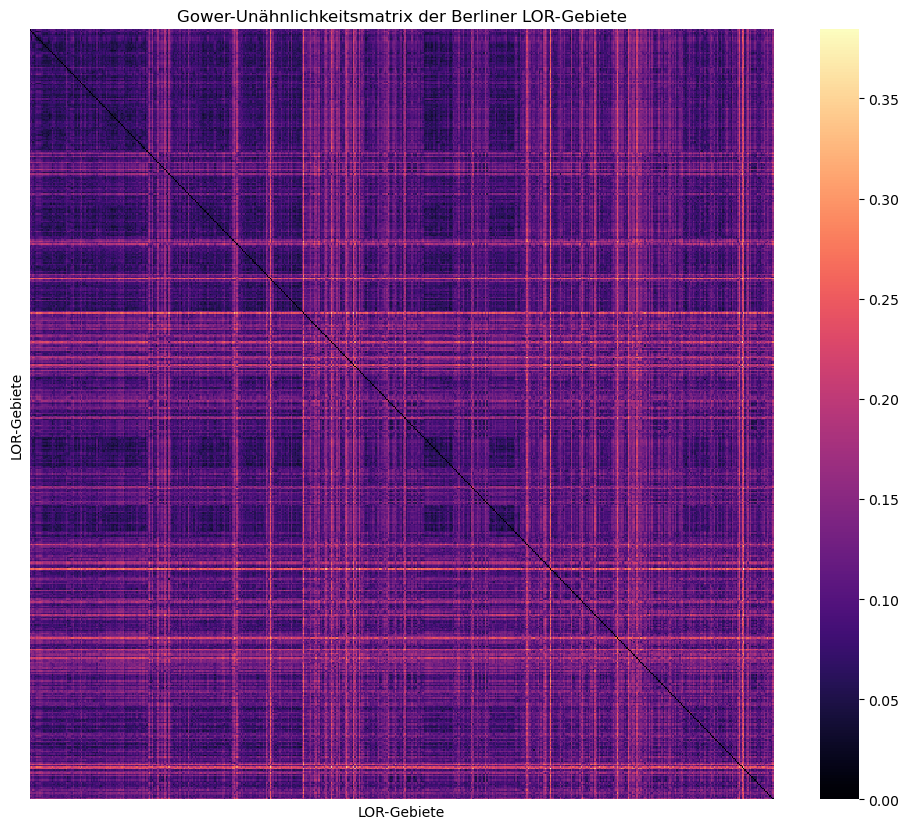

In [94]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

sns.heatmap(
    distanzmatrix,
    cmap="magma",
    xticklabels=False,
    yticklabels=False
)

plt.title("Gower-Unähnlichkeitsmatrix der Berliner LOR-Gebiete")
plt.xlabel("LOR-Gebiete")
plt.ylabel("LOR-Gebiete")

plt.show()
#ohhhhhhhhh ganz schön viel output

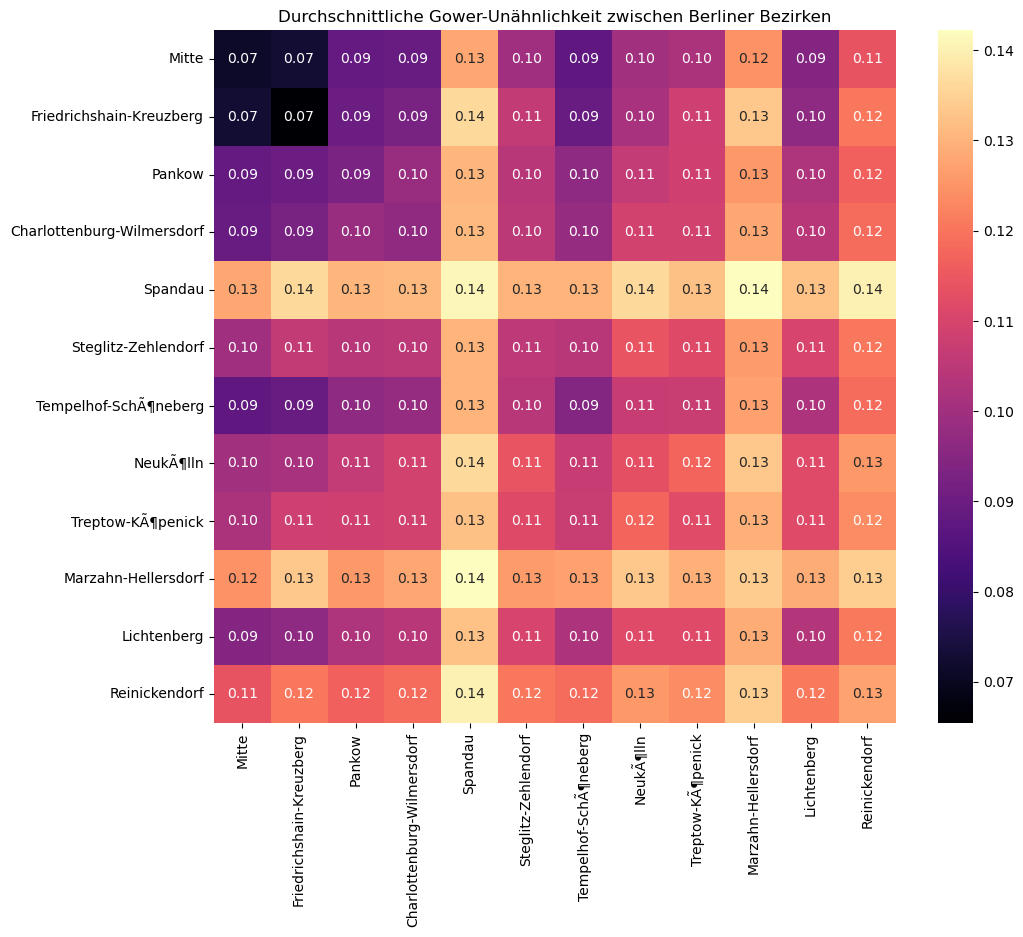

In [100]:
# Bezirkszuordnung der LOR-Gebiete
bezirk_map = merkmalsmatrix.set_index("LOR")["BEZ"]

# Leere Ergebnismatrix erstellen
bezirks_distanz = pd.DataFrame(
    index=bezirk_map.unique(),
    columns=bezirk_map.unique(),
    dtype=float
)

# Durchschnittliche Gower-Distanz zwischen Bezirken berechnen
for bez1 in bezirks_distanz.index:
    for bez2 in bezirks_distanz.columns:

        lor1 = bezirk_map[bezirk_map == bez1].index
        lor2 = bezirk_map[bezirk_map == bez2].index

        beurteilung = distanzmatrix.loc[lor1, lor2]

        bezirks_distanz.loc[bez1, bez2] = beurteilung.values.mean()

# Visualisierung
plt.figure(figsize=(11, 9))

sns.heatmap(
    bezirks_distanz.astype(float),
    annot=True,
    fmt=".2f",
    cmap="magma"
)

plt.title("Durchschnittliche Gower-Unähnlichkeit zwischen Berliner Bezirken")
plt.show()

#hier ist wenig unähnlichkeit...